In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "access_to_electricity/API_EG.ELC.ACCS.ZS_DS2_en_csv_v2_73003.csv",
    skiprows=4
)
world = gpd.read_file("data/naturalearth_lowres/naturalearth_lowres.shp")
africa = world[world["continent"] == "Africa"].copy()

In [3]:
df.columns

Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
       '2023', '2024', '2025', 'Unnamed: 70'],
      dtype='str')

In [4]:
df = df.rename(columns={"Country Code": "iso_a3"})
merged = africa.merge(right=df, on="iso_a3", how="left")
merged["changed"] = merged["2024"] - merged["2000"]
merged["changed_per_year"] = merged["changed"] / (2024-2000)

In [5]:
top = (
    merged[["name", "2000", "2024", "changed", "changed_per_year"]]
    .sort_values("changed", ascending=False)
    .head(10)
)
top

,name,2000,2024,changed,changed_per_year
34,eSwatini,20.4,89.3,68.9,2.870833
49,Rwanda,6.2,72.0,65.8,2.741667
4,Kenya,15.2,77.0,61.8,2.575000
8,Lesotho,4.3,60.6,56.3,2.345833
10,Botswana,26.5,80.2,53.7,2.237500
3,Somalia,2.1,54.4,52.3,2.179167
20,Ghana,43.7,91.9,48.2,2.008333
48,Uganda,7.4,55.3,47.9,1.995833
12,Senegal,37.7,82.9,45.2,1.883333
19,Togo,17.0,61.1,44.1,1.837500


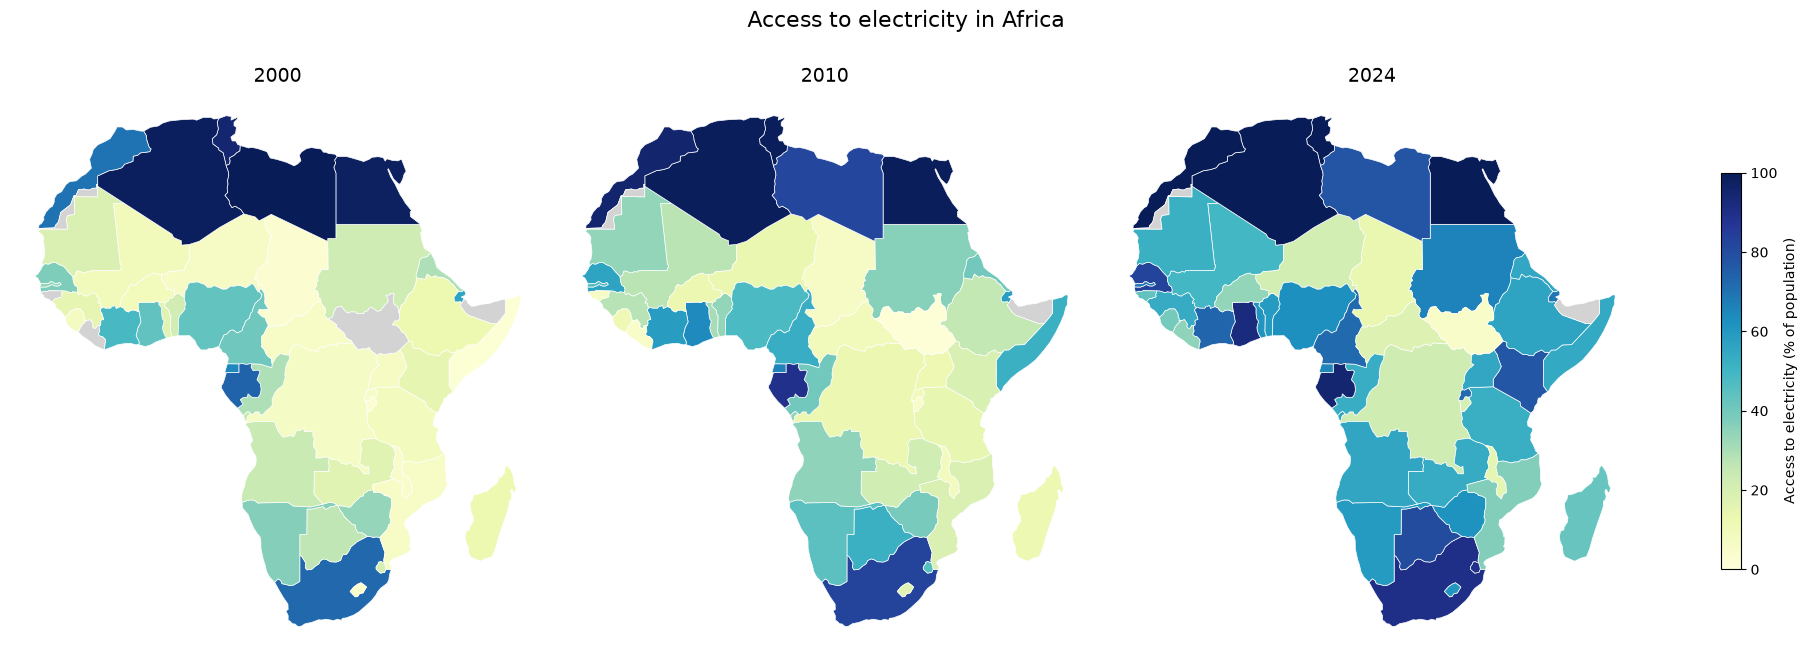

In [6]:
years = ["2000", "2010", "2024"]

fig, axes = plt.subplots(1, 3, figsize=(18, 7), constrained_layout=True)

for ax, year in zip(axes, years):
    merged.plot(
        ax=ax,
        column=year,
        cmap="YlGnBu",
        vmin=0, vmax=100,
        edgecolor="white",
        linewidth=0.5,
        missing_kwds={"color": "lightgrey"},
    )
    ax.set_title(year, fontsize=14)
    ax.set_axis_off()

sm = plt.cm.ScalarMappable(cmap="YlGnBu", norm=plt.Normalize(vmin=0, vmax=100))
fig.colorbar(sm, ax=axes, shrink=0.6, label="Access to electricity (% of population)")
fig.suptitle("Access to electricity in Africa", fontsize=16)
plt.show()

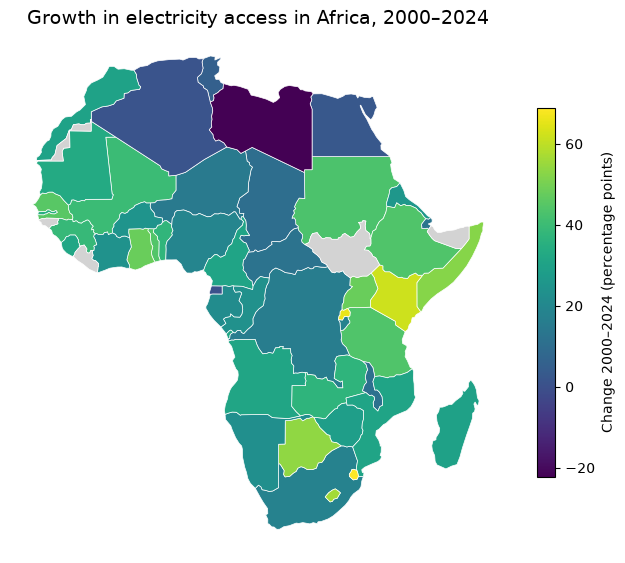

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
merged.plot(
    ax=ax,
    column="changed",
    cmap="viridis",
    edgecolor="white",
    linewidth=0.5,
    legend=True,
    legend_kwds={"label": "Change 2000–2024 (percentage points)", "shrink": 0.6},
    missing_kwds={"color": "lightgrey"},
)
ax.set_title("Growth in electricity access in Africa, 2000–2024", fontsize=14)
ax.set_axis_off()
plt.show()